In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = Path("../data/processed/airfoil_dataset_pilot.csv")
summary_path = Path("../data/processed/generation_summary_pilot.csv")

data = pd.read_csv(dataset_path)
summary = pd.read_csv(summary_path)

print("Dataset rows:", len(data))
print("Generation runs:", len(summary))

data.head()

Dataset rows: 373
Generation runs: 21


,airfoil,max_camber,camber_position,thickness,reynolds,alpha,CL,CD,CDp,CM,Top_Xtr,Bot_Xtr
0,NACA 0009,0.0,0.0,0.09,100000,0.0,-0.0000,0.01207,0.00479,0.0000,1.0000,1.0
1,NACA 0009,0.0,0.0,0.09,100000,1.0,0.0345,0.01266,0.00538,0.0107,1.0000,1.0
2,NACA 0009,0.0,0.0,0.09,100000,2.0,0.2703,0.01300,0.00629,-0.0153,0.9336,1.0
3,NACA 0009,0.0,0.0,0.09,100000,3.0,0.4028,0.01237,0.00578,-0.0140,0.7572,1.0
4,NACA 0009,0.0,0.0,0.09,100000,4.0,0.4836,0.01363,0.00614,-0.0047,0.4891,1.0


In [10]:
print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isna().sum())

print("\nDuplicate rows:")
print(data.duplicated().sum())

print("\nUnique airfoils:")
print(data["airfoil"].unique())

print("\nUnique Reynolds numbers:")
print(sorted(data["reynolds"].unique()))

print("\nAngle range:")
print(data["alpha"].min(), "to", data["alpha"].max())

print("\nCL range:")
print(data["CL"].min(), "to", data["CL"].max())

print("\nCD range:")
print(data["CD"].min(), "to", data["CD"].max())

Dataset shape: (373, 12)

Columns:
['airfoil', 'max_camber', 'camber_position', 'thickness', 'reynolds', 'alpha', 'CL', 'CD', 'CDp', 'CM', 'Top_Xtr', 'Bot_Xtr']

Missing values:
airfoil            0
max_camber         0
camber_position    0
thickness          0
reynolds           0
alpha              0
CL                 0
CD                 0
CDp                0
CM                 0
Top_Xtr            0
Bot_Xtr            0
dtype: int64

Duplicate rows:
0

Unique airfoils:
<StringArray>
['NACA 0009', 'NACA 0015', 'NACA 2212', 'NACA 2412', 'NACA 2612', 'NACA 4415',
 'NACA 6412']
Length: 7, dtype: str

Unique Reynolds numbers:
[np.int64(100000), np.int64(200000), np.int64(500000)]

Angle range:
-6.0 to 12.0

CL range:
-0.7673 to 1.6577

CD range:
0.0053 to 0.14463


In [11]:
summary[
    [
        "airfoil",
        "reynolds",
        "expected_points",
        "converged_points",
        "coverage_percent",
        "status"
    ]
]

,airfoil,reynolds,expected_points,converged_points,coverage_percent,status
0,NACA 0009,100000,19,19,100.000000,success
1,NACA 0009,200000,19,0,0.000000,failed: XFOIL timed out for NACA 0009 at Re = ...
2,NACA 0009,500000,19,19,100.000000,success
3,NACA 0015,100000,19,19,100.000000,success
4,NACA 0015,200000,19,19,100.000000,success
5,NACA 0015,500000,19,16,84.210526,success
6,NACA 2212,100000,19,19,100.000000,success
7,NACA 2212,200000,19,19,100.000000,success
8,NACA 2212,500000,19,19,100.000000,success
9,NACA 2412,100000,19,19,100.000000,success


In [12]:
print("Average coverage:")
print(summary["coverage_percent"].mean())

print("\nMinimum coverage:")
print(summary["coverage_percent"].min())

print("\nWorst runs:")
display(
    summary.sort_values("coverage_percent").head(10)
)

Average coverage:
93.48370927318294

Minimum coverage:
0.0

Worst runs:


,airfoil,reynolds,expected_points,converged_points,coverage_percent,status
1,NACA 0009,200000,19,0,0.000000,failed: XFOIL timed out for NACA 0009 at Re = ...
5,NACA 0015,500000,19,16,84.210526,success
14,NACA 2612,500000,19,18,94.736842,success
17,NACA 4415,500000,19,18,94.736842,success
19,NACA 6412,200000,19,18,94.736842,success
20,NACA 6412,500000,19,18,94.736842,success
3,NACA 0015,100000,19,19,100.000000,success
2,NACA 0009,500000,19,19,100.000000,success
7,NACA 2212,200000,19,19,100.000000,success
8,NACA 2212,500000,19,19,100.000000,success


In [13]:
counts = (
    data.groupby(["airfoil", "reynolds"])
    .size()
    .reset_index(name="rows")
)

counts

,airfoil,reynolds,rows
0,NACA 0009,100000,19
1,NACA 0009,500000,19
2,NACA 0015,100000,19
3,NACA 0015,200000,19
4,NACA 0015,500000,16
5,NACA 2212,100000,19
6,NACA 2212,200000,19
7,NACA 2212,500000,19
8,NACA 2412,100000,19
9,NACA 2412,200000,19


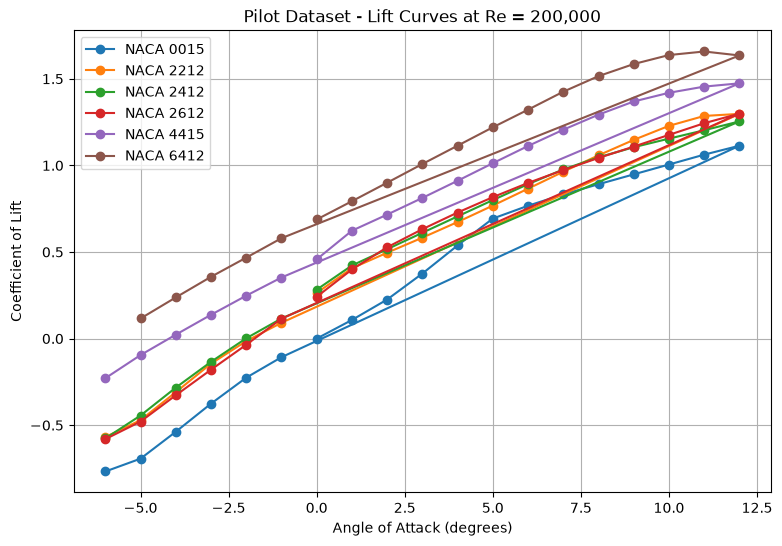

In [14]:
subset = data[data["reynolds"] == 200000]

plt.figure(figsize=(9, 6))

for airfoil, group in subset.groupby("airfoil"):
    plt.plot(
        group["alpha"],
        group["CL"],
        marker="o",
        label=airfoil
    )

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Coefficient of Lift")
plt.title("Pilot Dataset - Lift Curves at Re = 200,000")
plt.grid()
plt.legend()
plt.show()

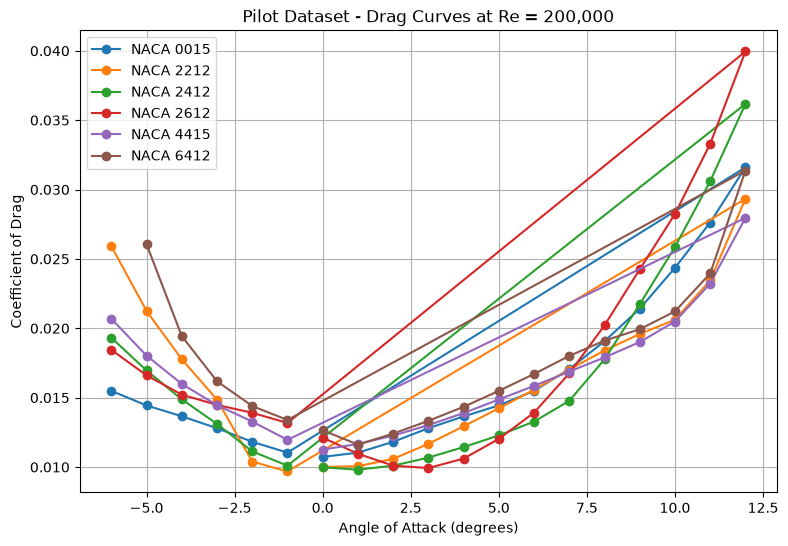

In [15]:
plt.figure(figsize=(9, 6))

for airfoil, group in subset.groupby("airfoil"):
    plt.plot(
        group["alpha"],
        group["CD"],
        marker="o",
        label=airfoil
    )

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Coefficient of Drag")
plt.title("Pilot Dataset - Drag Curves at Re = 200,000")
plt.grid()
plt.legend()
plt.show()

In [21]:
expected_angles = set(range(-6, 13))

for (airfoil, reynolds), group in data.groupby(
    ["airfoil", "reynolds"]
):
    actual_angles = set(group["alpha"].astype(int))

    missing_angles = sorted(
        expected_angles - actual_angles
    )

    if missing_angles:
        print(
            airfoil,
            "| Re =",
            reynolds,
            "| Missing angles:",
            missing_angles
        )

NACA 0015 | Re = 500000 | Missing angles: [-3, -1, 1]
NACA 2612 | Re = 500000 | Missing angles: [-2]
NACA 4415 | Re = 500000 | Missing angles: [7]
NACA 6412 | Re = 200000 | Missing angles: [-6]
NACA 6412 | Re = 500000 | Missing angles: [1]


In [22]:
summary[
    (summary["airfoil"] == "NACA 0009")
    & (summary["reynolds"] == 200000)
]

,airfoil,reynolds,expected_points,converged_points,coverage_percent,status
1,NACA 0009,200000,19,0,0.0,failed: XFOIL timed out for NACA 0009 at Re = ...
